TODO

adicionar transporte de ekman na figura no lugar dos vetores de corrente geostrófica

In [25]:
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import numpy as np
import gsw

from utils import get_shelf_edge, subplots_structure, nearest, prepare_eddies2plot, set_figure, make_map
from load_profiles import load_vertical_profiles

In [26]:
proj=ccrs.PlateCarree()
extent=[-47.5, -37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour
secGloc = (-43.072, -23.033)
secGloc = (-43.072, -23.033)
idate = '2022-03-01'
edate = '2022-04-01'
lon_range = extent[:2]
lat_range = extent[2:]
time_range = pd.date_range(idate, edate, freq='1D')

depfile = '../data/gebco_2019.nc'
# before plot the map, get the sheld edge contour
shelf_edge = get_shelf_edge(depfile=depfile, extent=extent)

datadir = '../data/sanagu2022/merge/'
ds = xr.open_mfdataset(f"{datadir}/*.nc", concat_dim='time', combine='nested')

# selecting only cells with precipitation higher than 0
# ds = ds.load().where(ds['prec'] > 0, drop=True)
ds = ds.rename({'longitude': 'lon', 'latitude': 'lat'})

In [27]:
ds2 = xr.open_mfdataset(f"{datadir}/*.nc", concat_dim='time', combine='nested')
ds2

<xarray.Dataset>
Dimensions:     (time: 91, latitude: 100, longitude: 200)
Coordinates:
  * time        (time) datetime64[ns] 2022-01-01T12:00:00 ... 2022-04-01T12:0...
    step        timedelta64[ns] 00:00:00
    surface     int64 0
  * latitude    (latitude) float64 -29.95 -29.85 -29.75 ... -20.25 -20.15 -20.05
  * longitude   (longitude) float64 -49.95 -49.85 -49.75 ... -30.15 -30.05
    valid_time  (time) datetime64[ns] 2022-01-01T12:00:00 ... 2022-04-01T12:0...
Data variables:
    prec        (time, latitude, longitude) float32 dask.array<chunksize=(1, 100, 200), meta=np.ndarray>
    prmsl       (time, latitude, longitude) float32 dask.array<chunksize=(1, 100, 200), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             consensus
    GRIB_centreDescription:  Consensus
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             Consensus
    history:                 2023-03-14T08:18:12 GRIB to CDM+CF via cfgrib-0....

In [28]:
dict_casts = load_vertical_profiles()

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


# preparing precipitation dataset

In [29]:
ds_daily = ds.resample(time='1D').mean()
# -- sea surface temperature in Celsius
ds_plot = ds_daily.prec.sel(lon=slice(-47.5, -37.5), lat=slice(-20, -28), )


# selecting days to take a composite view after and before cold front
ds_composite_before = ds_daily.sel(time=['2022-03-10', 
                                        '2022-03-11', 
                                        '2022-03-12']).mean(dim='time')
ds_composite_before = ds_composite_before.prec.sel(lon=slice(-47.5, -37.5), lat=slice(-28, -20), )


# selecting days to take a composite view after and before cold front
ds_composite_between = ds_daily.sel(time=['2022-03-13', 
                                          '2022-03-11', 
                                          '2022-03-17']).mean(dim='time')
ds_composite_between = ds_composite_between.prec.sel(lon=slice(-47.5, -37.5), lat=slice(-28, -20), )

ds_composite_after = ds_daily.sel(time=['2022-03-28', 
                                        '2022-03-29', 
                                        '2022-03-30']).mean(dim='time')
ds_composite_after = ds_composite_after.prec.sel(lon=slice(-47.5, -37.5), lat=slice(-28, -20), )

# preparing the ekman transport dataset

In [35]:
def ekman_transport(tau_x, tau_y, y, H=30, rho_water=1028., tdim=0):
    """Calculate Ekman pumping from wind-stress curl.

    Args:
        curl_tau: Wind stress curl (N/m^3), 2d or 3d (for time series).
        y: Latitude grid (degrees), 2d.
        mld: mixed layer depth (m)

    Notes:
        f = Coriolis frequency (rad/s), latitude dependent.
        rho = Ocean water density (1028 kg/m^3).
        H = the surface ekman layer. It could also be the mixed layer depth

    """
    f = gsw.f(y)
    f = np.expand_dims(f, tdim)

    # gets the depth-integrated cross-shelf velocity as in Brink (2016), which is in m²/s
    Ue = (tau_y / (f*rho_water))
    Ve = - (tau_x / (f*rho_water))

    # multiply by H to get the total transport in m³/s
    Ue = Ue * H
    Ve = Ve * H
    
    return Ue, Ve

In [36]:
# loading wind shear dataset
ds = xr.open_dataset(f"{datadir}../adaptor.mars.internal-1676897226.091868-11964-3-275141a3-cb3d-400e-8961-0e947d2ca463.nc")

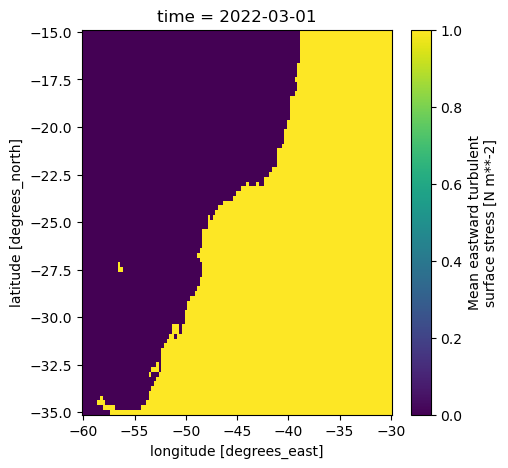

In [37]:
# creating ocean/land maks from SST
mask = xr.where(ds['sst'].isel(time=0).isnull(), 0, 1)

# empty matrix
masked = xr.ones_like(ds['metss'])
# replicating mask through time
masked[:,...] = mask

# checking
masked.isel(time=0).plot.pcolormesh(x='longitude', y='latitude', figsize=(5,5))

In [41]:
# gridding coordinates, necessary for wind_stress_curl() function
x,y = np.meshgrid(ds['longitude'].values, ds['latitude'].values)

# using H = 30 as an average value of the MLD computed from hydrographic data
Ue,Ve = ekman_transport(ds['metss'], ds['mntss'], y, H=30, rho_water=1028., tdim=0)

ds['Uek'] = (('time', 'latitude', 'longitude'), Ue.data)
ds['Vek'] = (('time', 'latitude', 'longitude'), Ve.data)

ds['ekmanTransport'] = np.sqrt(ds['Uek'] ** 2 + ds['Vek']**2)

ds['windstress'] = np.sqrt(ds['metss'] ** 2 + ds['mntss']**2)

ds['Uek'].attrs['long_name'] = 'zonal Ekman transport'
ds['Uek'].attrs['units'] = 'm**3 s**-1'

ds['Vek'].attrs['long_name'] = 'meridional Ekman transport'
ds['Vek'].attrs['units'] = 'm**3 s**-1'

ds['ekmanTransport'].attrs['long_name'] = 'Ekman transport'
ds['ekmanTransport'].attrs['units'] = r'm$^3$ s$^{-1}$'

# ds['ekmanTransportMagnitude'] = np.sqrt(ds['Uek']**2 + ds['Vek']**2)
# ds['ekmanTransportMagnitude'].attrs['long_name'] = 'Ekman transport magnitude'
# ds['ekmanTransportMagnitude'].attrs['units'] = r'm$^2$ s$^{-1}$'

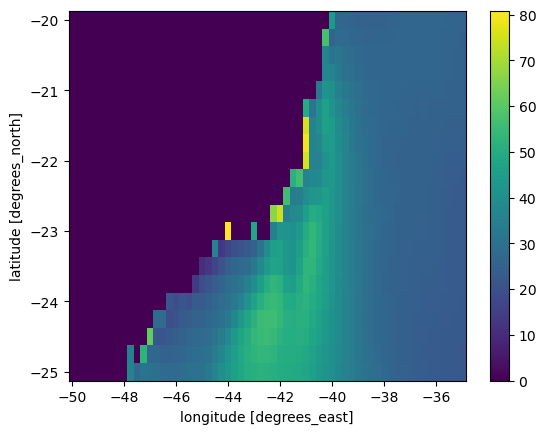

In [40]:
(ds['ekmanTransport'] * masked).mean(dim='time').sel(longitude=slice(-50, -35), latitude=slice(-20, -25)).plot.pcolormesh()

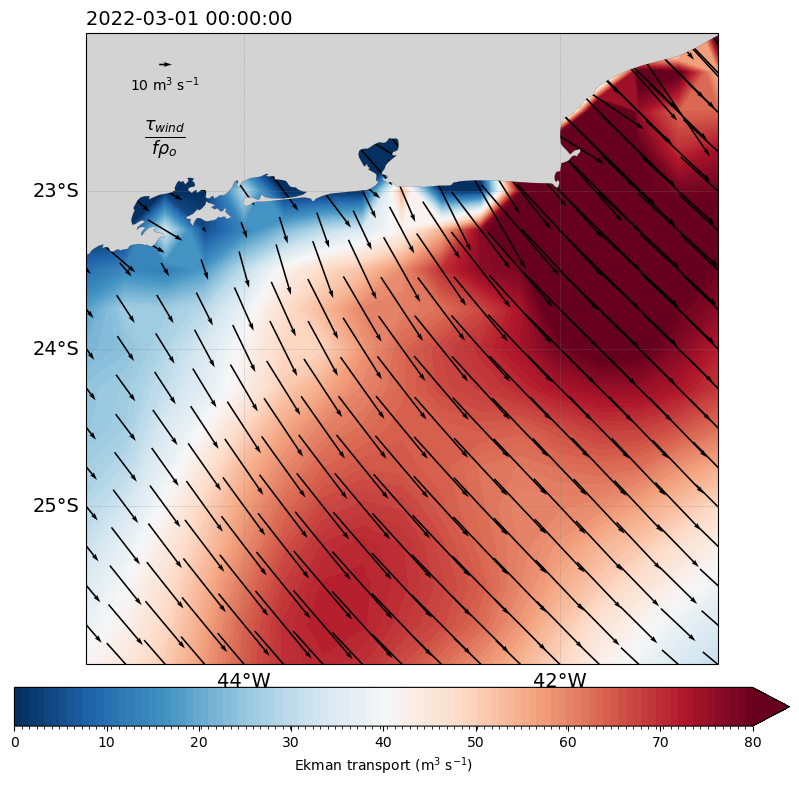

In [50]:
cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': 0.03, 'label': 'cbar', 
             'spacing': 'proportional' # for proportional ticks
            }

vmin,vmax = 0, 80

dates = pd.date_range(start='2022-03-01', end='2022-03-31')

for day in dates[:1]:
    fig,axes = subplots_structure(1,1, (10,10), 1)
    ax = axes[0]
    
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent([-45, -41, -26, -22])
    # ax.plot(shelf['lon'], shelf['lat'], c='k', ls='--', lw=.5)
    
    # specific settings for the variable in analysis
    levels = np.linspace(vmin,vmax, 100)
    cbar_kwargs['label'] = f"{ds['ekmanTransport'].attrs['long_name']} ({ds['ekmanTransport'].attrs['units']})"
    cbar_kwargs['ticks'] = np.arange(vmin,vmax+1, 10)
    (ds['ekmanTransport'] * masked).sel(time=day).plot.contourf(ax=ax, x='longitude', y='latitude', 
                                                                                   vmin=vmin, vmax=vmax,
                                                                                   levels=levels,
                                                                                   cbar_kwargs=cbar_kwargs, 
                                                                                   cmap='RdBu_r')

    q = ds.sel(time=day).plot.quiver(ax=ax, x='longitude', y='latitude', u='Uek', v='Vek',
                                                       scale=500, width=.0025, color='k', add_guide=False)
    quiverkey=[-44.5, -22.2, 10, r'10 m$^3$ s$^{-1}$']
    quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
    qk = ax.quiverkey(q,
                      quiverkey[0], # x position
                      quiverkey[1], # y position
                      quiverkey[2], # unit 
                      quiverkey[3], # label
                      **quiverkey_kws).set_zorder(11)
    
    ax.text(-44.5, -22.7, r'$\frac{\tau_{wind}}{f \rho_o}$', fontsize=18, ha='center')
    
    ax.set_title('')
    ax.set_title(day, loc='left', fontsize=14)
    
    t = pd.to_datetime(day).strftime("%Y-%m-%d")
    fig.patch.set_alpha(1.0)


# Plotting everything together

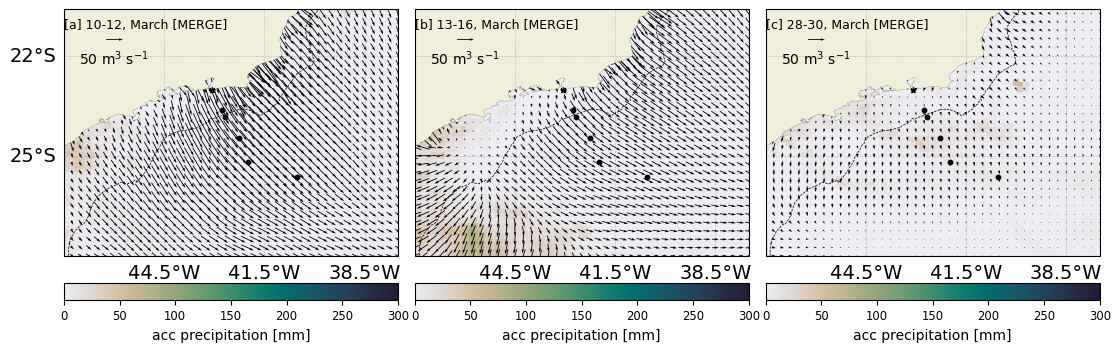

In [66]:
# plotting composites
fig = plt.figure(figsize=(30/2.54, 16/2.54)) # proportion for paper (15/2.54, 8/2.54)

ax_before = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
ax_before = make_map(ax=ax_before, extent=extent)
ax_before.set_extent(extent)

ax_between = fig.add_subplot(1, 3, 2, projection=ccrs.PlateCarree())
ax_between = make_map(ax=ax_between, extent=extent, drawlineleft=False)
ax_between.set_extent(extent)

ax_after = fig.add_subplot(1, 3, 3, projection=ccrs.PlateCarree())
ax_after = make_map(ax=ax_after, extent=extent, drawlineleft=False)
ax_after.set_extent(extent)

axes = [ax_before, ax_between, ax_after]

pc1 = ds_composite_before.plot.pcolormesh(ax=ax_before,
                                        vmin=0,
                                        vmax=300,
                                        cmap=cmo.rain,
                                        add_colorbar=False)

pc3 = ds_composite_between.plot.pcolormesh(ax=ax_between,
                                        vmin=0,
                                        vmax=300,
                                        cmap=cmo.rain,
                                        add_colorbar=False)


pc2 = ds_composite_after.plot.pcolormesh(ax=ax_after,
                                        vmin=0,
                                        vmax=300,
                                        cmap=cmo.rain,
                                        add_colorbar=False)

_ = [ax.set_title('') for ax in axes]

quiver_kwargs = dict(scale=1000, width=.0025, color='k', add_guide=False)

q = ds.sel(time=['2022-03-10', 
             '2022-03-11', 
             '2022-03-12']).mean(dim='time').plot.quiver(ax=ax_before, 
                                                         x='longitude', y='latitude', 
                                                         u='Uek', v='Vek',
                                                         **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = ax_before.quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

q = ds.sel(time=slice('2022-03-13', '2022-03-17')).mean(dim='time').plot.quiver(ax=ax_between, 
                                                                                 x='longitude', y='latitude', 
                                                                                 u='Uek', v='Vek',
                                                                                 **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = ax_between.quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

q = ds.sel(time=slice('2022-03-28', '2022-03-30')).mean(dim='time').plot.quiver(ax=ax_after, 
                                                                                x='longitude', y='latitude', 
                                                                                u='Uek', v='Vek',
                                                                                **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = ax_after.quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

# adding marker and shelf edge contour
for ax in axes:
    ax.scatter(secGloc[0], secGloc[1], marker='*', s=15, c='k', zorder=5)
    ax.plot(shelf_edge['lon'], shelf_edge['lat'], ls='--', c='k', lw='0.5')

    # plotting
    for cast,values in dict_casts.items():
        prof = values['prof']
        str_time = values['time'].strftime("%m/%d")
        xlon = values['xlon']
        ylat = values['ylat']
        c = 'k'
        ax.scatter(xlon, ylat, c=c, s=10)

for pc in [pc1, pc2, pc3]:
    cb = plt.colorbar(pc, orientation="horizontal", pad=0.05)
    cb.set_label(label='acc precipitation [mm]', size=10)
    cb.ax.tick_params(labelsize='small')

_ = [ax.set_title('') for ax in [ax_before, ax_between, ax_after]]

ax_before.set_title('[a] 10-12, March [MERGE]', loc='left', fontsize=9, y=.89)
ax_between.set_title('[b] 13-16, March [MERGE]', loc='left', fontsize=9, y=.89)
ax_after.set_title('[c] 28-30, March [MERGE]', loc='left', fontsize=9, y=.89)

plt.tight_layout()
plt.subplots_adjust(top=0.952,
                    bottom=0.094,
                    left=0.083,
                    right=0.96,
                    hspace=0.2,
                    wspace=0.05)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_supp_precip.png', bbox_inches="tight", dpi=300)

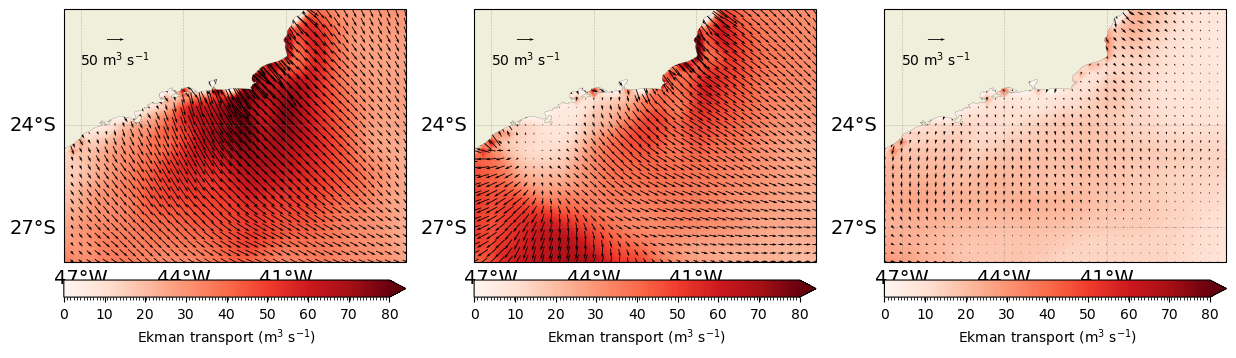

In [80]:
fig,axes = subplots_structure(3,1,(15,8),3)

for ax in axes:
    ax = make_map(ax=ax)
    ax.set_extent(extent)

(ds['ekmanTransport'] * masked).sel(time=['2022-03-10', 
                                          '2022-03-11', 
                                          '2022-03-12']).mean(dim='time').plot.contourf(ax=axes[0], x='longitude', y='latitude', 
                                                                                          vmin=vmin, vmax=vmax,
                                                                                          levels=levels,
                                                                                          cbar_kwargs=cbar_kwargs, 
                                                                                          cmap='Reds')

(ds['ekmanTransport'] * masked).sel(time=slice('2022-03-13', '2022-03-17')).mean(dim='time').plot.contourf(ax=axes[1], x='longitude', y='latitude', 
                                                                                          vmin=vmin, vmax=vmax,
                                                                                          levels=levels,
                                                                                          cbar_kwargs=cbar_kwargs, 
                                                                                          cmap='Reds')

(ds['ekmanTransport'] * masked).sel(time=slice('2022-03-28', '2022-03-30')).mean(dim='time').plot.contourf(ax=axes[2], x='longitude', y='latitude', 
                                                                                          vmin=vmin, vmax=vmax,
                                                                                          levels=levels,
                                                                                          cbar_kwargs=cbar_kwargs, 
                                                                                          cmap='Reds')



quiver_kwargs = dict(scale=1000, width=.0025, color='k', add_guide=False)

q = ds.sel(time=['2022-03-10', 
             '2022-03-11', 
             '2022-03-12']).mean(dim='time').plot.quiver(ax=axes[0], 
                                                         x='longitude', y='latitude', 
                                                         u='Uek', v='Vek',
                                                         **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = axes[0].quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

q = ds.sel(time=slice('2022-03-13', '2022-03-17')).mean(dim='time').plot.quiver(ax=axes[1], 
                                                                                 x='longitude', y='latitude', 
                                                                                 u='Uek', v='Vek',
                                                                                 **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = axes[1].quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)

q = ds.sel(time=slice('2022-03-28', '2022-03-30')).mean(dim='time').plot.quiver(ax=axes[2], 
                                                                                x='longitude', y='latitude', 
                                                                                u='Uek', v='Vek',
                                                                                **quiver_kwargs)

quiverkey=[-46, -21.5, 50, r'50 m$^3$ s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')
qk = axes[2].quiverkey(q,
                  quiverkey[0], # x position
                  quiverkey[1], # y position
                  quiverkey[2], # unit 
                  quiverkey[3], # label
                  **quiverkey_kws).set_zorder(11)